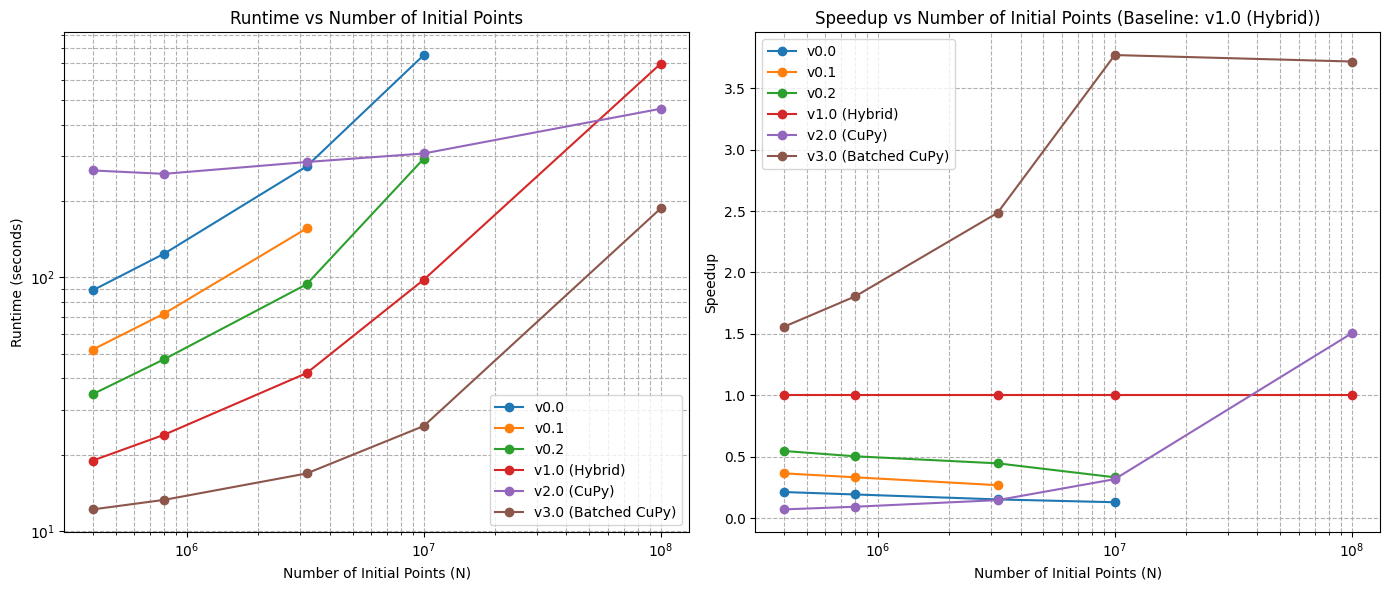

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

version_times_vs_n = [
    [400_000, 89, 52, 34.7, 22.6, 264, 19.0, 12.2],
    [800_000, 124, 72, 47.6, 28.1, 256, 24, 13.3],
    [3_200_000, 274, 156, 94, 55.0, 285, 42, 16.9],
    [10_000_000, 752, np.nan, 294, 104, 308, 98, 26],
    [100_000_000, np.nan, np.nan, np.nan, 811, 462, 695, 187],
]
labels = [
    "N",
    "v0.0",
    "v0.1",
    "v0.2",
    "v4.0",
    "v2.0 (CuPy)",
    "v1.0 (Hybrid)",
    "v3.0 (Batched CuPy)",
]
speed_baseline_col = "v1.0 (Hybrid)"
df = pd.DataFrame(version_times_vs_n, columns=labels)
for version in labels[1:]:
    speedup_col = f"speedup_{version}"
    df[speedup_col] = df[speed_baseline_col] / df[version]

# Define versions and colors
versions = [
    "v0.0",
    "v0.1",
    "v0.2",
    # "v4.0",
    "v1.0 (Hybrid)",
    "v2.0 (CuPy)",
    "v3.0 (Batched CuPy)",
]
colors = [f"C{i}" for i in range(len(versions))]

# Plot subplot of runtimes vs N and speedups vs N
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Loop over versions for runtime
for i, version in enumerate(versions):
    ax1.plot(
        df["N"],
        df[version],
        marker="o",
        label=version,
        color=colors[i],
        # alpha=alpha,
    )

ax1.set_xscale("log")
ax1.set_yscale("log")


def x_ticks_helper(vals: list[float]) -> list[str]:
    labels = []
    for x in vals:
        if x == 0:
            labels.append("0")
        else:
            exp = int(np.log10(abs(x)))
            mant = x / (10**exp)
            labels.append(rf"{mant:.1f} $\times$ 10$^{{{exp}}}$")
    return labels


ax1.set_xlabel("Number of Initial Points (N)")
ax1.set_ylabel("Runtime (seconds)")
ax1.set_title("Runtime vs Number of Initial Points")
ax1.grid(True, which="both", ls="--")
ax1.legend()

ax2.set_xscale("log")
# ax2.set_yscale("log")
for i, version in enumerate(versions):
    speedup_col = f"speedup_{version}"
    ax2.plot(
        df["N"],
        df[speedup_col],
        marker="o",
        label=version,
        color=colors[i],
        # alpha=alpha,
    )
ax2.set_xlabel("Number of Initial Points (N)")
ax2.set_ylabel("Speedup")
ax2.set_title(f"Speedup vs Number of Initial Points (Baseline: {speed_baseline_col})")
ax2.grid(True, which="both", ls="--")
ax2.legend()

plt.tight_layout()

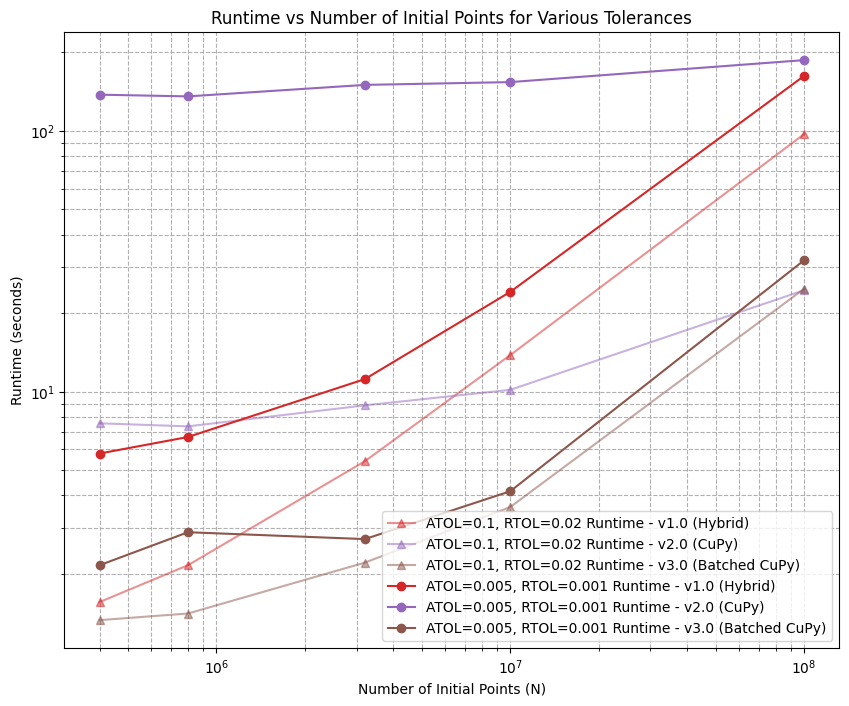

In [ ]:
version_times_vs_tols_vs_n = [
    [400_000, 0.1, 0.02, 1.21, 7.56, 1.56, 1.33],
    [400_000, 0.05, 0.01, 1.54, 14.09, 1.04, 1.19],
    [400_000, 0.025, 0.005, 2.35, 28.56, 1.63, 1.45],
    [400_000, 0.01, 0.002, 4.59, 70.26, 3.31, 1.88],
    [400_000, 0.005, 0.001, 7.92, 137.64, 5.79, 2.16],
    [800_000, 0.1, 0.02, 1.9, 7.36, 2.16, 1.41],
    [800_000, 0.05, 0.01, 2.31, 14.09, 1.57, 1.43],
    [800_000, 0.025, 0.005, 3.23, 27.05, 2.17, 1.42],
    [800_000, 0.01, 0.002, 5.85, 67.51, 3.90, 1.71],
    [800_000, 0.005, 0.001, 9.91, 135.58, 6.70, 2.89],
    [3_200_000, 0.1, 0.02, 6.36, 8.86, 5.41, 2.21],
    [3_200_000, 0.05, 0.01, 7.02, 16.75, 5.09, 2.02],
    [3_200_000, 0.025, 0.005, 8.4, 32.32, 6.07, 2.20],
    [3_200_000, 0.01, 0.002, 11.57, 75.74, 8.14, 2.42],
    [3_200_000, 0.005, 0.001, 16.48, 150.06, 11.17, 2.72],
    [10_000_000, 0.1, 0.02, 16.03, 10.16, 13.81, 3.61],
    [10_000_000, 0.05, 0.01, 16.66, 17.83, 14.49, 3.37],
    [10_000_000, 0.025, 0.005, 18.90, 33.89, 16.67, 3.64],
    [10_000_000, 0.01, 0.002, 22.57, 81.74, 20.21, 3.92],
    [10_000_000, 0.005, 0.001, 26.47, 153.8, 24.13, 4.15],
    [100_000_000, 0.1, 0.02, 122.77, 24.48, 97.17, 24.80],
    [100_000_000, 0.05, 0.01, 137.37, 34.09, 110.23, 26.27],
    [100_000_000, 0.025, 0.005, 149.81, 52.58, 122.70, 27.35],
    [100_000_000, 0.01, 0.002, 178.95, 104.03, 145.45, 29.49],
    [100_000_000, 0.005, 0.001, 200.79, 186.74, 162.40, 31.89],
]

df_tols = pd.DataFrame(
    version_times_vs_tols_vs_n,
    columns=[
        "N",
        "ATOL",
        "RTOL",
        "v1.0",
        "v2.0 (CuPy)",
        "v1.0 (Hybrid)",
        "v3.0 (Batched CuPy)",
    ],
)

tolmat = np.array(
    [
        [0.1, 0.02],
        # [0.05, 0.01],
        # [0.025, 0.005],
        # [0.01, 0.002],
        [0.005, 0.001],
    ],
)

markers = ["o", "^", "s", "x", "D", "v"]
alphas = [0.3, 0.5, 0.7, 0.9, 1.0]

versions = ["v1.0 (Hybrid)", "v2.0 (CuPy)", "v3.0 (Batched CuPy)"]
markers = ["^", "o"]
alphas = [0.5, 1.0]
colors = ["C3", "C4", "C5"]
fig, ax1 = plt.subplots(1, 1, figsize=(10, 8))
for i in range(tolmat.shape[0]):
    atol = tolmat[i, 0]
    rtol = tolmat[i, 1]
    df_subset = df_tols[(df_tols["ATOL"] == atol) & (df_tols["RTOL"] == rtol)]

    label_runtime = rf"ATOL={atol}, RTOL={rtol} Runtime"
    label_speedup = rf"ATOL={atol}, RTOL={rtol} Speedup"

    _m = markers[i % len(markers)]
    _a = alphas[i % len(alphas)]
    for j, version in enumerate(versions):
        ax1.plot(
            df_subset["N"],
            df_subset[version],
            marker=_m,
            label=f"{label_runtime} - {version}",
            color=colors[j],
            alpha=_a,
        )


ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("Number of Initial Points (N)")
ax1.set_ylabel("Runtime (seconds)")
ax1.set_title("Runtime vs Number of Initial Points for Various Tolerances")
ax1.grid(True, which="both", ls="--")
ax1.legend()